In [ ]:
!pip install ultralytics

In [ ]:
import numpy as np
import pandas as pd
import cv2
from ultralytics import YOLO

from sklearn.utils import shuffle
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt

import warnings

warnings.simplefilter('ignore')

In [ ]:
model = YOLO("yolov8m.pt")

In [ ]:
results=model.predict(source="image3.jpg",
              save=True, conf=0.2,iou=0.5)


image 1/1 /content/image3.jpg: 384x640 8 persons, 11 cars, 2 benchs, 3395.2ms
Speed: 19.2ms preprocess, 3395.2ms inference, 11.6ms postprocess per image at shape (1, 3, 384, 640)
Results saved to runs/detect/predict2


In [ ]:
print(results)

[ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
keypoints: None
masks: None
names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant'

In [ ]:
result = results[0]
box = result.boxes[0]

In [ ]:
for result in results:
    boxes = result.boxes  # Boxes object for bbox outputs
    masks = result.masks  # Masks object for segmentation masks outputs
    probs = result.probs  # Class probabilities for classification outputs

In [ ]:
for box in result.boxes:
    class_id = result.names[box.cls[0].item()]
    cords = box.xyxy[0].tolist()
    cords = [round(x) for x in cords]
    conf = round(box.conf[0].item(), 2)
    print("Object type:", class_id)
    print("Coordinates:", cords)
    print("Probability:", conf)
    print("---")

Object type: car
Coordinates: [1678, 644, 1919, 869]
Probability: 0.93
---
Object type: car
Coordinates: [1439, 646, 1734, 880]
Probability: 0.92
---
Object type: car
Coordinates: [1, 872, 411, 1076]
Probability: 0.91
---
Object type: car
Coordinates: [1183, 621, 1451, 936]
Probability: 0.91
---
Object type: car
Coordinates: [953, 601, 1209, 926]
Probability: 0.9
---
Object type: car
Coordinates: [1672, 263, 1808, 363]
Probability: 0.78
---
Object type: bench
Coordinates: [671, 491, 848, 565]
Probability: 0.75
---
Object type: person
Coordinates: [692, 235, 727, 350]
Probability: 0.7
---
Object type: person
Coordinates: [649, 265, 680, 349]
Probability: 0.64
---
Object type: car
Coordinates: [1548, 165, 1647, 238]
Probability: 0.64
---
Object type: car
Coordinates: [1603, 212, 1721, 301]
Probability: 0.63
---
Object type: car
Coordinates: [1866, 419, 1919, 539]
Probability: 0.57
---
Object type: car
Coordinates: [1765, 322, 1919, 461]
Probability: 0.47
---
Object type: person
Coordinat

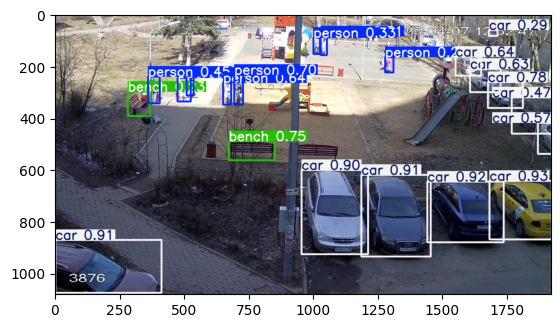

In [ ]:
# Plotting results
plot = results[0].plot()
plot = cv2.cvtColor(plot, cv2.COLOR_BGR2RGB)
plt.imshow(plot)